# Vision — Deteksi Cacat Produk (anomali PatchCore + klasifikasi supervised)
**Kapan dipakai:** foto produk di lini produksi, cacat jarang dan bentuknya beragam, atau contoh
cacat sedikit. Dua cara dibandingkan di data yang sama:
1. **Anomali gaya PatchCore** (tanpa contoh cacat): fitur tiap "patch" gambar NORMAL dari ResNet
   (layer2 + layer3) disimpan sebagai memory bank. Gambar baru dinilai dari jarak patch-nya ke
   patch normal terdekat. Skor gambar = jarak terbesar; jarak per patch = peta panas.
2. **Supervised**: embedding CLIP → LogisticRegression normal vs cacat (butuh contoh cacat).

Penyederhanaan dari PatchCore asli: memory bank diambil acak 10% (bukan coreset), ResNet18
(bukan WideResNet50) supaya cepat di laptop.

**Data demo:** MVTec AD kategori `bottle` (256 px): 209 normal + 30 cacat untuk latih, 53 gambar
test. Metrik: AUROC gambar.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.nn import functional
from torchvision import models, transforms
from transformers import CLIPModel, CLIPProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/defect_mvtec_bottle"   # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "Z:/GEMASTIK-DATABASE/pretrained"
CLIP_FOLDER = f"{PRETRAINED}/clip_b32"

PATH_COL = "path"       # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"        # "normal" / "cacat"
DEFECT_NAME = "cacat"
BANK_FRACTION = 0.10    # bagian patch normal yang disimpan (lebih besar = akurat, lebih lambat)
N_VALIDATION = 20       # gambar normal yang TIDAK masuk bank, untuk menentukan ambang
BATCH_SIZE = 16
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())
print(train["jenis"].value_counts())

train: (239, 3) | test: (53, 2)
label
normal    209
cacat      30
Name: count, dtype: int64
jenis
good             209
broken_small      13
contamination      9
broken_large       8
Name: count, dtype: int64


## Fitur patch dengan ResNet18
Gambar 256x256 → layer2 (peta 32x32, 128 saluran) dan layer3 (16x16, 256 saluran, diperbesar
jadi 32x32) → digabung = 384 angka per patch. Dirata-rata 3x3 supaya patch tahu tetangganya.

In [4]:
resnet = models.resnet18(weights=None)
resnet.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
resnet = resnet.to(DEVICE)
resnet.eval()
prepare = transforms.Compose([transforms.ToTensor(),
                              transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

### Fitur patch gambar normal (bahan memory bank)
`N_VALIDATION` gambar normal pertama disisihkan untuk menentukan ambang.

In [5]:
def patch_features(paths):
    # path gambar -> tensor (jumlah gambar, 32, 32, 384) di CPU
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = []
        for path in paths[start:start + BATCH_SIZE]:
            images.append(prepare(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")))
        batch = torch.stack(images).to(DEVICE)
        with torch.no_grad():
            stem = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(batch))))   # awal ResNet
            layer2 = resnet.layer2(resnet.layer1(stem))
            layer3 = resnet.layer3(layer2)
            layer2 = functional.avg_pool2d(layer2, 3, 1, 1)
            layer3 = functional.avg_pool2d(layer3, 3, 1, 1)
            layer3 = functional.interpolate(layer3, size=layer2.shape[-2:], mode="bilinear")
        features = torch.cat([layer2, layer3], dim=1)
        batches.append(features.permute(0, 2, 3, 1).cpu())
    return torch.cat(batches)


train_normal = train[train[TARGET] == "normal"].reset_index(drop=True)
bank_paths = list(train_normal[PATH_COL][N_VALIDATION:])
validation_paths = list(train_normal[PATH_COL][:N_VALIDATION])
bank_features = patch_features(bank_paths)
print("fitur bank:", bank_features.shape)

fitur bank: torch.Size([189, 32, 32, 384])


## Memory bank
Semua patch gambar normal dijajarkan jadi satu tabel besar, lalu diambil 10% secara acak.

In [6]:
all_patches = bank_features.reshape(-1, bank_features.shape[-1])
generator = torch.Generator().manual_seed(SEED)
order = torch.randperm(len(all_patches), generator=generator)
n_kept = int(len(all_patches) * BANK_FRACTION)
memory_bank = all_patches[order[:n_kept]].to(DEVICE)
print("patch normal:", len(all_patches), "| disimpan di bank:", len(memory_bank))

patch normal: 193536 | disimpan di bank: 19353


## Skor anomali
Tiap patch: jarak ke patch terdekat di bank. Peta panas = jarak semua patch (32x32).
Skor gambar = jarak patch terbesar. Ambang = skor tertinggi gambar normal validasi.

In [7]:
def anomaly_scores(paths):
    # kembalikan (skor tiap gambar, peta jarak tiap gambar 32x32)
    features = patch_features(paths)
    scores = []
    maps = []
    for number in range(len(features)):
        patches = features[number].reshape(-1, features.shape[-1]).to(DEVICE)
        distances = torch.cdist(patches, memory_bank).min(dim=1).values   # ke patch terdekat
        distance_map = distances.reshape(features.shape[1], features.shape[2])
        maps.append(distance_map.cpu().numpy())
        scores.append(distances.max().item())
        # alternatif tahan noise: scores.append(distances.topk(10).values.mean().item())
    return np.array(scores), np.array(maps)


validation_scores, _ = anomaly_scores(validation_paths)
test_scores, test_maps = anomaly_scores(list(test[PATH_COL]))
threshold = validation_scores.max()
print("skor validasi normal: min", round(validation_scores.min(), 2),
      "maks", round(threshold, 2))
print("skor test: min", round(test_scores.min(), 2), "maks", round(test_scores.max(), 2))

skor validasi normal: min 1.12 maks 1.52
skor test: min 1.13 maks 3.91


## Peta panas contoh (5 skor tertinggi + 3 terendah)
Merah = patch yang jauh dari semua patch normal = kemungkinan cacat.

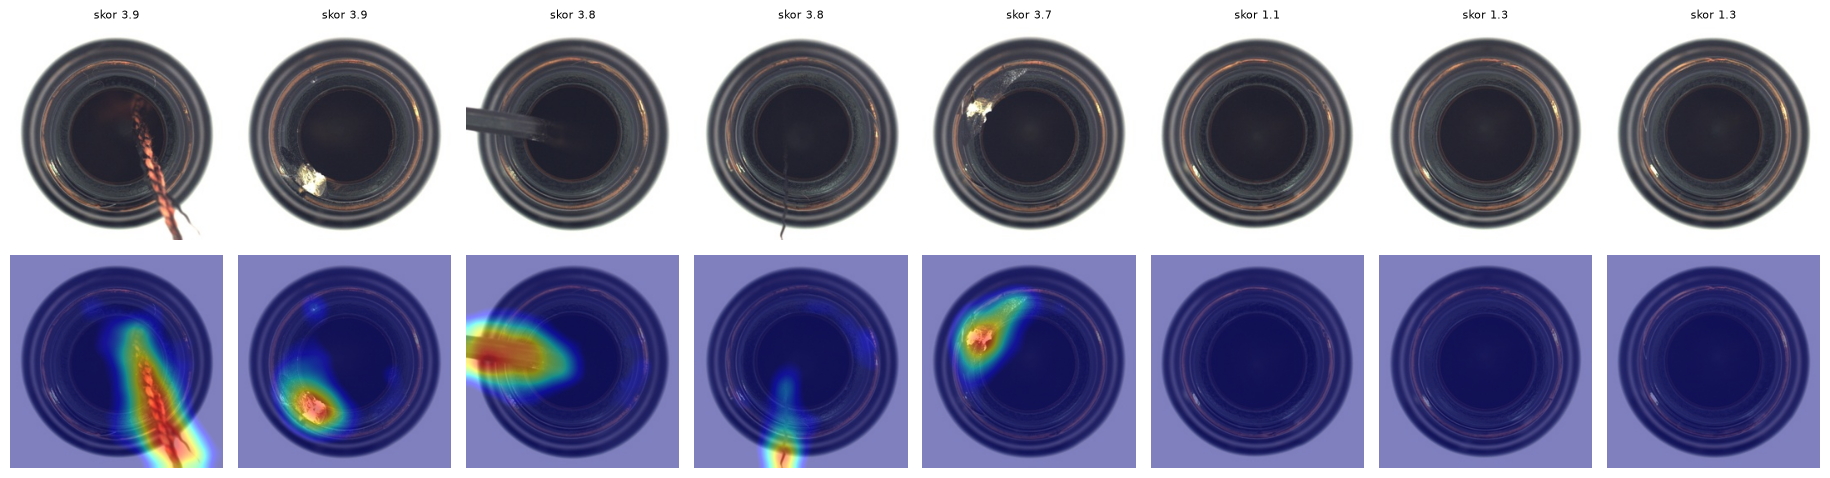

In [8]:
order = np.argsort(test_scores)
examples = list(order[::-1][:5]) + list(order[:3])
fig, axes = plt.subplots(2, len(examples), figsize=(2.3 * len(examples), 5))
for column, row in enumerate(examples):
    image = Image.open(f"{DATA_FOLDER}/{test[PATH_COL][row]}").convert("RGB")
    heatmap = cv2.resize(test_maps[row], image.size)
    heatmap = cv2.GaussianBlur(heatmap, (0, 0), 4)     # haluskan supaya enak dilihat
    axes[0, column].imshow(image)
    axes[0, column].set_title(f"skor {round(test_scores[row], 1)}", fontsize=8)
    axes[1, column].imshow(image)
    axes[1, column].imshow(heatmap, cmap="jet", alpha=0.5, vmin=validation_scores.min(),
                           vmax=test_scores.max())
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.savefig("peta_panas.png", dpi=110)
plt.show()

## Cara 2: supervised — embedding CLIP + LogisticRegression
Memakai semua gambar `train.csv` (normal + cacat). Kelas cacat jauh lebih sedikit, maka
`class_weight="balanced"`.

In [9]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)


def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = []
        for path in paths[start:start + BATCH_SIZE]:
            images.append(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB"))
        encoded = processor(images=images, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            output = clip.get_image_features(**encoded)
        batches.append(output.pooler_output.cpu().numpy())
    return np.concatenate(batches)


X_train = embed_images(list(train[PATH_COL]))
X_test = embed_images(list(test[PATH_COL]))
y_train = (train[TARGET] == DEFECT_NAME).astype(int)

model = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=3000, C=0.05, class_weight="balanced"))
model.fit(X_train, y_train)
defect_proba = model.predict_proba(X_test)[:, 1]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Submission
Label memakai cara 1 (PatchCore). Kolom `skor` boleh dihapus/diganti sesuai format soal.

In [10]:
submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = np.where(test_scores > threshold, "cacat", "normal")
submission["skor"] = test_scores
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label,skor
0,1,cacat,2.408657
1,2,normal,1.295135
2,3,normal,1.429932
3,4,normal,1.318860
4,5,cacat,3.362238


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)

In [11]:
test_key = pd.read_csv(TEST_KEY_CSV)
y_test = (test_key[TARGET] == DEFECT_NAME).astype(int)
guess = (test_scores > threshold).astype(int)
print("AUROC PatchCore    :", round(roc_auc_score(y_test, test_scores), 3))
print("dengan ambang -> akurasi:", round(accuracy_score(y_test, guess), 3),
      "| F1 cacat:", round(f1_score(y_test, guess), 3))
print("AUROC CLIP + LogReg:", round(roc_auc_score(y_test, defect_proba), 3))

score_table = pd.DataFrame()
score_table["jenis"] = test_key["jenis"]
score_table["skor"] = test_scores
print(score_table.groupby("jenis")["skor"].mean())

AUROC PatchCore    : 1.0
dengan ambang -> akurasi: 0.943 | F1 cacat: 0.957
AUROC CLIP + LogReg: 0.998
jenis
broken_large     3.367972
broken_small     3.156820
contamination    2.802448
good             1.399789
Name: skor, dtype: float64
